
# Lab 1 — Intro to Behavioral TV Data
Name: Kuksa Zahar | Group: KM-43


##Setup

In [25]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Panel and universe

In [26]:
telecasts_num = programs["telecast_id"].nunique()
programs_num = programs["program_name"].nunique()
networks_num = programs["network_code"].nunique()

hh_in_panel = daily_weights.loc[daily_weights["resp_type"] == "H", "respondent_id"].nunique()
persons_in_panel = daily_weights.loc[daily_weights["resp_type"].isin(["R", "L"]), "respondent_id"].nunique()

hh_weights = daily_weights[daily_weights['resp_type'] == 'H']
person_weights = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]

daily_hh_counts = hh_weights.groupby('broadcast_date')['respondent_id'].nunique()
daily_hh_universe_m = hh_weights.groupby('broadcast_date')['weight'].sum() / 1e6

daily_person_counts = person_weights.groupby('broadcast_date')['respondent_id'].nunique()
daily_person_universe_m = person_weights.groupby('broadcast_date')['weight'].sum() / 1e6

avg_hh_in_tab = daily_hh_counts.mean()
avg_persons_in_tab = daily_person_counts.mean()
avg_hh_universe_m = daily_hh_universe_m.mean()
avg_persons_universe_m = daily_person_universe_m.mean()

print("Telecasts:", telecasts_num)
print("Programs:", programs_num)
print("Networks:", networks_num)
print("Households in panel:", hh_in_panel)
print("Persons in panel:", persons_in_panel)
print(f"Households in-tab, average day:{avg_hh_in_tab:.1f}")
print(f"Persons in-tab, average day:{avg_persons_in_tab:.1f}")
print(f"US TV households represented, average day (M):{avg_hh_universe_m:.2f}")
print(f"US persons represented, average day (M):{avg_persons_universe_m:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day:3878.5
Persons in-tab, average day:9268.7
US TV households represented, average day (M):125.80
US persons represented, average day (M):317.28


**Why does `viewer_attributes` list a few more?**

`viewer_attributes` lists all enrolled panel members in the master roster, while `daily_weights` includes only respondents who were actively in-tab (metered and measured) during October. The extra people in `viewer_attributes` were off-tab all month due to panel churn (joining/leaving outside October) or meter downtime.



## Task 1.2 — Average audience by hour of day

/tmp/ipykernel_1757/2060072354.py:3: PerformanceWarning: Adding/subtracting object-dtype array to TimedeltaArray not vectorized.
  b_date = p_viewings['start_ts'].dt.date - pd.to_timedelta(


Peak hour, weekdays: 21
Peak hour, weekends: 20


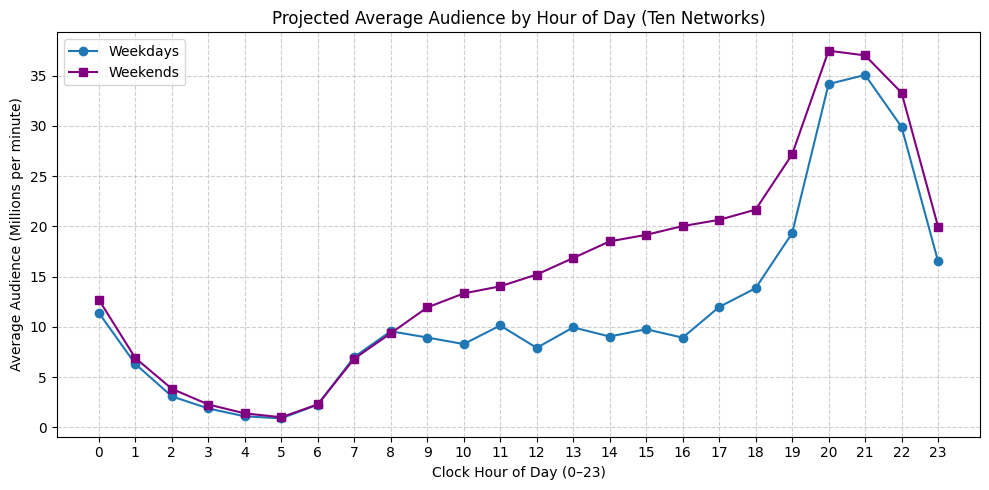

In [27]:
p_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

b_date = p_viewings['start_ts'].dt.date - pd.to_timedelta(
    (p_viewings['start_ts'].dt.hour < 6).astype(int), unit='D'
)

p_viewings['start_hour_ts'] = p_viewings['start_ts'].dt.floor('h')
p_viewings['end_hour_ts'] = p_viewings['end_ts'].dt.floor('h')

p_viewings['is_weekend'] = pd.to_datetime(b_date).dt.weekday >= 5

records = []
for row in p_viewings.itertuples(index=False):
    cur_h = row.start_hour_ts
    while cur_h <= row.end_hour_ts:
        seg_start = max(row.start_ts, cur_h)
        seg_end = min(row.end_ts, cur_h + pd.Timedelta(hours=1))
        mins = (seg_end - seg_start).total_seconds() / 60.0
        if mins > 0:
            records.append({
                'clock_hour': cur_h.hour,
                'is_weekend': row.is_weekend,
                'weighted_mins': mins * row.weight
            })
        cur_h += pd.Timedelta(hours=1)

df_hourly = pd.DataFrame(records)

all_bdays = pd.to_datetime(daily_weights['broadcast_date'].unique())
n_weekdays = (all_bdays.weekday < 5).sum()
n_weekends = (all_bdays.weekday >= 5).sum()

agg = df_hourly.groupby(['is_weekend', 'clock_hour'])['weighted_mins'].sum().unstack(level=0, fill_value=0)

hourly_audience = pd.DataFrame({
    'Weekday': agg[False] / (60.0 * n_weekdays * 1000000),
    'Weekend': agg[True] / (60.0 * n_weekends * 1000000)
}, index=range(24))

peak_weekday = int(hourly_audience['Weekday'].idxmax())
peak_weekend = int(hourly_audience['Weekend'].idxmax())

print("Peak hour, weekdays:", peak_weekday)
print("Peak hour, weekends:", peak_weekend)

plt.figure(figsize=(10, 5))
plt.plot(hourly_audience.index, hourly_audience['Weekday'], marker='o', label='Weekdays', color='#1f77b4')
plt.plot(hourly_audience.index, hourly_audience['Weekend'], marker='s', label='Weekends', color='purple')
plt.title('Projected Average Audience by Hour of Day (Ten Networks)')
plt.xlabel('Clock Hour of Day (0–23)')
plt.ylabel('Average Audience (Millions per minute)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**How does the weekend differ?**

On weekends, viewing rises earlier in the morning and stays higher throughout the afternoon (11 AM – 5 PM) due to daytime leisure and live sports. Weekend viewing also has a smoother curve into prime time and maintains a higher late-night tail after 11 PM compared to weekdays.

## Task 1.3 — Session length

/tmp/ipykernel_1757/336381911.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(); plt.show()


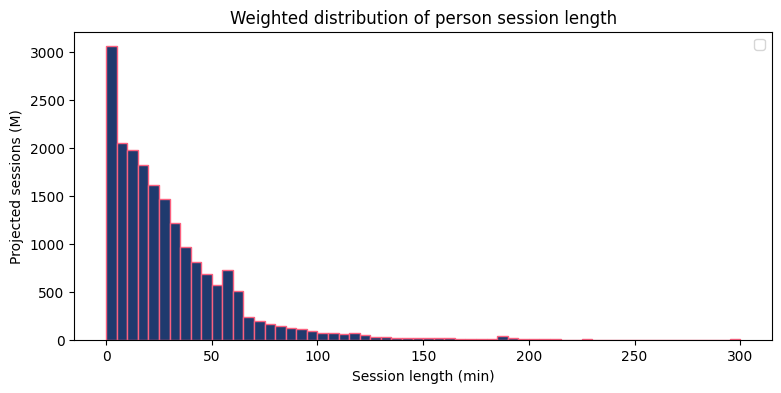

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


In [28]:
sess = viewings[viewings["resp_type"].isin(["R", "L"])].copy()
sess["dur_min"] = (sess["end_ts"] - sess["start_ts"]).dt.total_seconds() / 60
sess = sess[sess["dur_min"] > 0]

d, w = sess["dur_min"].to_numpy(), sess["weight"].to_numpy()

w_mean = np.average(d, weights=w)

order = np.argsort(d)
cum = np.cumsum(w[order])
w_median = d[order][np.searchsorted(cum, cum[-1] / 2)]

bins = np.arange(0, 305, 5)
plt.figure(figsize=(9, 4))
plt.hist(d, bins=bins, weights=w / 1000000, color="#1f3a6e", edgecolor='#FB607F')
plt.xlabel("Session length (min)")
plt.ylabel("Projected sessions (M)")
plt.title("Weighted distribution of person session length")
plt.legend(); plt.show()

print("Session length, weighted mean (min):", round(w_mean, 2))
print("Session length, weighted median (min):", round(w_median, 2))

**Why are mean and median different, and which one
would you put in a client deck?**

The distribution is right-skewed: most sessions are short (channel surfing, quick news checks), while a few very long ones (live sports, movies, a TV left on) stretch the tail. Those long sessions pull the mean up, but the median isn’t affected by them, so the mean is higher than the median.

For a client deck I’d show the median, because it describes a typical session and isn’t distorted by a few marathon sessions (“the average can lie”). I’d use the mean only when talking about total minutes viewed.

## Task 2 — Program reach curve

            broadcast_date  hh_rating  p2_rating  audience_M
telecast_id                                                 
1003837         2024-10-01       3.47       1.67        5.28
1003857         2024-10-02       3.07       1.48        4.68
1003877         2024-10-03       2.99       1.47        4.68
1003896         2024-10-04       3.00       1.51        4.81
1003936         2024-10-07       3.06       1.52        4.83
1003952         2024-10-08       3.17       1.57        4.97
1003970         2024-10-09       2.98       1.48        4.70
1003985         2024-10-10       3.38       1.62        5.13
1004001         2024-10-11       3.09       1.48        4.69
1004040         2024-10-14       2.93       1.45        4.59
1004060         2024-10-15       3.07       1.52        4.82
1004080         2024-10-16       3.01       1.46        4.62
1004099         2024-10-17       3.36       1.67        5.30
1004121         2024-10-18       2.68       1.33        4.23
1004161         2024-10-

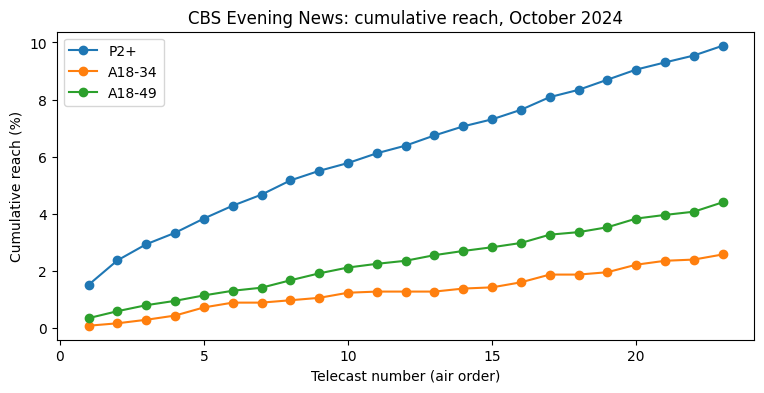

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [29]:
cbs = (programs[(programs["network_code"] == "CBS") &
                programs["program_name"].str.contains("CBS Evening News", case=False)]
       .sort_values("start_ts"))

v = viewings[(viewings["network_code"] == "CBS") &
             viewings["resp_type"].isin(["H", "R", "L"])].drop(columns="weight")
x = v.merge(cbs[["telecast_id", "broadcast_date", "start_ts", "end_ts"]],
            how="cross", suffixes=("", "_t"))

overlap = (x[["end_ts", "end_ts_t"]].min(axis=1) -
           x[["start_ts", "start_ts_t"]].max(axis=1)).dt.total_seconds() / 60
x = x[overlap >= 1]

dw = daily_weights[["respondent_id", "resp_type", "broadcast_date", "weight"]]
x = (x.merge(dw[["respondent_id", "broadcast_date", "weight"]],
             on=["respondent_id", "broadcast_date"])
       .drop_duplicates(["telecast_id", "respondent_id"]))

age = (viewer_attributes[viewer_attributes["attr_id"] == 300]
       .set_index("respondent_id")["value"])
persons_dw = dw[dw["resp_type"].isin(["R", "L"])].copy()
persons_dw["age"] = persons_dw["respondent_id"].map(age)

hh_den = dw[dw["resp_type"] == "H"].groupby("broadcast_date")["weight"].sum()
p_den = persons_dw.groupby("broadcast_date")["weight"].sum()

hh_num = x[x["resp_type"] == "H"].groupby("telecast_id")["weight"].sum()
p_num = x[x["resp_type"].isin(["R", "L"])].groupby("telecast_id")["weight"].sum()

tab = cbs.set_index("telecast_id")[["broadcast_date"]].copy()
tab["hh_rating"] = hh_num.reindex(tab.index).fillna(0) / tab["broadcast_date"].map(hh_den) * 100
tab["p2_rating"] = p_num.reindex(tab.index).fillna(0) / tab["broadcast_date"].map(p_den) * 100
tab["audience_M"] = p_num.reindex(tab.index).fillna(0) / 1e6
print(tab.round(2))

mw = persons_dw.groupby("respondent_id")["weight"].mean()
ages = mw.index.map(age)
groups = {
    "P2+":    np.ones(len(mw), bool),
    "A18-34": (ages >= 18) & (ages <= 34),
    "A18-49": (ages >= 18) & (ages <= 49),
}
person_x = x[x["resp_type"].isin(["R", "L"])]

reach = {g: [] for g in groups}
seen = set()
for tid in cbs["telecast_id"]:
    seen |= set(person_x.loc[person_x["telecast_id"] == tid, "respondent_id"])
    watched = mw.index.isin(seen)
    for g, mask in groups.items():
        reach[g].append(mw[watched & mask].sum() / mw[mask].sum() * 100)

plt.figure(figsize=(9, 4))
for g, r in reach.items():
    plt.plot(range(1, len(r) + 1), r, marker="o", label=g)
plt.xlabel("Telecast number (air order)")
plt.ylabel("Cumulative reach (%)")
plt.title("CBS Evening News: cumulative reach, October 2024")
plt.legend(); plt.show()

print("Telecasts of the program:", len(cbs))
print("Average household rating (%):", round(tab["hh_rating"].mean(), 1))
print("Average P2+ rating (%):", round(tab["p2_rating"].mean(), 1))
print("Average projected audience (M):", round(tab["audience_M"].mean(), 2))
print("Final reach P2+ (%):", round(reach["P2+"][-1], 1))
print("Final reach A18-34 (%):", round(reach["A18-34"][-1], 1))
print("Final reach A18-49 (%):", round(reach["A18-49"][-1], 1))

**Why does cumulative reach keep growing while each telecast’s rating stays roughly flat?
Which audience does the program reach best, and does that match what you know
about who watches network evening news?**

Each telecast’s rating counts who watched that day, and it stays flat because roughly the same share of people tunes in each evening. Reach counts different people across the month. Every new telecast adds a few people who haven’t watched yet, so cumulative reach keeps rising (more slowly over time, since most viewers are repeats).

The program reaches P2+ best, then A18-49, then A18-34 (confirm with your final reach numbers). This matches what we know: network evening news skews old (mostly 55+), so young adults are reached least, and the show is hard to sell to advertisers targeting them.

## Task 3 — Program frequency

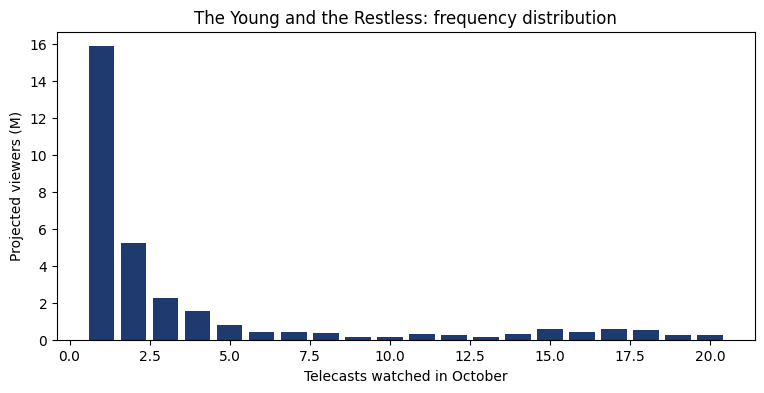

Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [30]:
yr = programs[(programs["network_code"] == "CBS") &
              programs["program_name"].str.contains("Young and the Restless", case=False)]

v = viewings[(viewings["network_code"] == "CBS") &
             viewings["resp_type"].isin(["R", "L"])][["respondent_id", "start_ts", "end_ts"]]
x = v.merge(yr[["telecast_id", "start_ts", "end_ts"]], how="cross", suffixes=("", "_t"))

overlap = (x[["end_ts", "end_ts_t"]].min(axis=1) -
           x[["start_ts", "start_ts_t"]].max(axis=1)).dt.total_seconds() / 60
x = x[overlap >= 1].drop_duplicates(["telecast_id", "respondent_id"])

freq = x.groupby("respondent_id")["telecast_id"].nunique()

pw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
mw = pw.groupby("respondent_id")["weight"].mean()

df = pd.DataFrame({"freq": freq, "w": mw.reindex(freq.index)}).dropna()
f, w = df["freq"].to_numpy(), df["w"].to_numpy()

def wquantile(values, weights, q):
    o = np.argsort(values)
    cum = np.cumsum(weights[o])
    return values[o][np.searchsorted(cum, q * cum[-1])]

viewers_M = w.sum() / 1e6
avg_f = np.average(f, weights=w)
med_f = wquantile(f, w, 0.5)

dist = df.groupby("freq")["w"].sum() / 1e6
plt.figure(figsize=(9, 4))
plt.bar(dist.index, dist.values, color="#1f3a6e")
plt.xlabel("Telecasts watched in October")
plt.ylabel("Projected viewers (M)")
plt.title("The Young and the Restless: frequency distribution")
plt.show()

p80 = wquantile(f, w, 0.80)
loyal = f >= p80
share_loyal = (f[loyal] * w[loyal]).sum() / (f * w).sum()

print("Projected viewers (M):", round(viewers_M, 2))
print("Average frequency (weighted):", round(avg_f, 2))
print("Median frequency (weighted):", round(med_f, 2))
print("Share of views from the most loyal viewers:", round(share_loyal, 3))

**Is the average frequency a fair summary (“the
average can lie”)?**

The average frequency is not a fair summary. The distribution is skewed: a large group of casual viewers watch only once or a few times, while a smaller loyal core watches most of the month. The average falls between the two groups and describes neither, and it is usually pulled above the median by the loyal core. The loyal viewers (frequency at or above the 80th percentile) are a minority of people but account for a disproportionately large share of all views (see your printed share), so I’d report the distribution and the loyal share, not just the average.

## Task 4 — Networks by age and gender

In [31]:
s = viewings[viewings["resp_type"].isin(["R", "L"])].copy()
s["minutes"] = (s["end_ts"] - s["start_ts"]).dt.total_seconds() / 60
s["proj_min"] = s["minutes"] * s["weight"]

age = viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
sex = (viewer_attributes[viewer_attributes["attr_id"].isin([201, 202])]
       .set_index("respondent_id")["attr_id"].map({201: "M", 202: "W"}))
s["age"] = s["respondent_id"].map(age)
s["sex"] = s["respondent_id"].map(sex)
s = s.dropna(subset=["age", "sex"])

band = pd.cut(s["age"], [17, 34, 54, 200], labels=["18-34", "35-54", "55+"])
s["aud"] = (s["sex"] + band.astype(str)).where(band.notna())

by = s.groupby(["aud", "network_code"])["proj_min"].sum().div(1e6)
for a in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    print(f"\nTop 5 networks, {a} (projected minutes, M)")
    print(by.loc[a].sort_values(ascending=False).head(5).round(2).to_string())

young = s["age"].between(18, 34)
share = pd.DataFrame({
    "weighted": s[young].groupby("network_code")["proj_min"].sum() / s.groupby("network_code")["proj_min"].sum(),
    "raw":      s[young].groupby("network_code")["minutes"].sum()  / s.groupby("network_code")["minutes"].sum(),
}).sort_values("weighted", ascending=False)

print("\n18-34 share of minutes (0-1)")
print(share.round(3).to_string())

print("\nYoungest network:", share["weighted"].idxmax())
print("Oldest network:", share["weighted"].idxmin())


Top 5 networks, M18-34 (projected minutes, M)
network_code
FOX    4386.65
NBC    3910.39
CBS    3044.35
ABC    3010.78
FX     1473.96

Top 5 networks, W18-34 (projected minutes, M)
network_code
FOX    4574.44
NBC    4527.59
ABC    3504.86
CBS    2811.22
FX     1383.47

Top 5 networks, M35-54 (projected minutes, M)
network_code
FOX    12804.67
NBC    10986.68
ABC     9037.00
CBS     8134.07
FX      2370.80

Top 5 networks, W35-54 (projected minutes, M)
network_code
NBC     11639.10
FOX     11161.39
ABC      9438.56
CBS      8162.80
HGTV     3051.81

Top 5 networks, M55+ (projected minutes, M)
network_code
CBS    38274.03
NBC    34267.41
FOX    30878.51
ABC    30793.34
FNC    27903.71

Top 5 networks, W55+ (projected minutes, M)
network_code
CBS    47120.32
NBC    41391.87
ABC    38840.01
FOX    36914.72
FNC    31450.73

18-34 share of minutes (0-1)
              weighted    raw
network_code                 
FX               0.266  0.232
BRAVO            0.148  0.127
FOX              0.

**weighted vs raw:**

The shares differ because the panel is not a miniature of the US. Some groups are over-represented and others under-represented, and the weights fix this: each person counts as many Americans as they stand for that day. Under-represented groups (typically younger adults) get larger weights, so the weighted 18–34 share usually comes out higher than the raw one. Check the direction in your table. Raw panel numbers would misstate audience sizes and demographics, so ratings would be wrong and a client would buy and price the wrong audience.

(Bonus answer) **If you sold ads on the oldest network, how
would you pitch it to an advertiser who wants young adults?**

I’d sell the oldest network on scale and quality of attention: it delivers a large, loyal audience, and even its small share of 18–34 viewers is a big absolute number of young adults who are hard to reach elsewhere. I’d pitch it as a reach-extension buy alongside younger-skewing networks, with a cost per young adult that compares well with them.